# Channel-flow snapshot distances
Compare early and late velocity fields, with an optional window from an independent simulation. This notebook does not change any training splits or launch training.

For each field, distance is `sqrt(mean_xyz((f(t + lag) - f(t))**2))` in its exported units. Equal-size windows use the same sampled pair offsets at each lag. Lower short-lag distances mean the field changes less between snapshots; they do **not** by themselves show simpler spatial structure or better predictability from pressure. Compare lags across simulations only if their snapshot cadence matches. Compare windows within each field, not raw distances between fields with different units.

Only sampled snapshots are read, with a small in-memory cache and no Dask. Statistics describe the sampled pairs; the bands are percentiles, not confidence intervals. The held-out test split is not used by default.

In [1]:
from functools import lru_cache

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

PRIMARY_STORE = 'simulations/flow_export/A1/data.zarr'
EXTERNAL_STORE = None  # Optional: S3 path in the same bucket/key format.
ENDPOINT = 'http://localhost:8333'
WINDOW_SIZE = 128
TRAIN_MAX_SAMPLES = 500  # Match the trial you want to inspect; None = full split.
LAGS = (1, 4, 16, 32, 64)  # In exported snapshots, not simulation time steps.
PAIRS_PER_LAG = 12
SEED = 0
COMPONENTS = ('ux', 'uy', 'uz', 'pp', 'critq')  # Export order: velocity, pressure, Q-criterion.

## Select windows
The defaults start at the trainer's train and validation split boundaries. Add other windows (for example, an unused middle interval or several candidate validation blocks) to `windows` using `(array, start_index)`. Arrays can be NumPy, CPU Torch tensors, or Zarr with layout `(time, channel, x, y, z)` and channels in `COMPONENTS` order. Choose windows that don't overlap your intended holdout, and use matching grids, units and sampling cadence for cross-simulation comparisons.

In [2]:
import s3fs
import zarr
from train_channel import compute_splits

fs = s3fs.S3FileSystem(profile='default', client_kwargs={'endpoint_url': ENDPOINT})

def open_source(path):
    return zarr.open_array(store=s3fs.S3Map(root=path, s3=fs), mode='r')

primary = open_source(PRIMARY_STORE)
splits = compute_splits(primary.shape[0])
train = splits['train'][:TRAIN_MAX_SAMPLES]
val = splits['val']
if WINDOW_SIZE > min(len(train), len(val)):
    raise ValueError('WINDOW_SIZE must fit in both the selected train and validation splits')
windows = {'early (train)': (primary, train.start), 'late (validation)': (primary, val.start)}
if EXTERNAL_STORE:
    external = open_source(EXTERNAL_STORE)
    if external.shape[2:] != primary.shape[2:]:
        raise ValueError('Expected the same spatial shape for the external simulation')
    windows['external simulation'] = (external, train.start)  # Adjust for its spin-up.
for label, (source, start) in windows.items():
    print(f'{label}: [{start}:{start + WINDOW_SIZE}) out of {source.shape[0]} snapshots')

early (train): [60:188) out of 4001 snapshots
late (validation): [3205:3333) out of 4001 snapshots


In [3]:
def lag_distances(windows, window_size, lags, pairs_per_lag, seed=0, progress=True):
    """Per-component RMS distances from matched within-window pairs."""
    if not windows or pairs_per_lag < 1 or not lags or any(not 0 < lag < window_size for lag in lags):
        raise ValueError('Provide windows, a positive pair count and lags in [1, window_size)')
    rng = np.random.default_rng(seed)
    offsets = {lag: np.sort(rng.choice(window_size - lag,
                                      size=min(pairs_per_lag, window_size - lag),
                                      replace=False)) for lag in lags}
    rows = []
    for label, (source, start) in windows.items():
        if len(source.shape) != 5 or source.shape[1] < len(COMPONENTS):
            raise ValueError(f'{label}: expected (time, channel, x, y, z) with fields {COMPONENTS}')
        if not 0 <= start <= source.shape[0] - window_size:
            raise ValueError(f'{label}: window falls outside the source')

        @lru_cache(maxsize=8)
        def snapshot(index):
            return np.asarray(source[index, :len(COMPONENTS)], dtype=np.float32)

        pairs = ((lag, start + int(i)) for lag, indices in offsets.items() for i in indices)
        total = sum(len(indices) for indices in offsets.values())
        for lag, i in tqdm(pairs, total=total, desc=label, unit='pair', disable=not progress):
            delta = snapshot(i + lag) - snapshot(i)
            np.square(delta, out=delta)
            rms = np.sqrt(delta.mean(axis=(1, 2, 3), dtype=np.float64))
            rows.extend({'window': label, 'lag': lag, 't0': i, 't1': i + lag,
                         'component': c, 'rms_distance': d} for c, d in zip(COMPONENTS, rms))
        snapshot.cache_clear()
    return pd.DataFrame(rows)

In [4]:
distances = lag_distances(windows, WINDOW_SIZE, LAGS, PAIRS_PER_LAG, seed=SEED)
summary = (distances.groupby(['window', 'component', 'lag'])['rms_distance']
           .agg(pairs='size', mean='mean', std='std', median='median',
                p10=lambda s: s.quantile(0.10), p90=lambda s: s.quantile(0.90))
           .reset_index())
summary

early (train):   0%|          | 0/60 [00:00<?, ?pair/s]

late (validation):   0%|          | 0/60 [00:00<?, ?pair/s]

,window,component,lag,pairs,mean,std,median,p10,p90
0,early (train),critq,1,12,1.814471,0.549950,1.752039,1.242362,2.522286
1,early (train),critq,4,12,1.651012,0.451476,1.545519,1.237769,1.983430
2,early (train),critq,16,12,1.972302,0.502665,2.007147,1.176591,2.532314
3,early (train),critq,32,12,2.032280,0.364840,2.142808,1.588805,2.356031
4,early (train),critq,64,12,1.963582,0.380283,2.027686,1.491901,2.396213
5,early (train),pp,1,12,0.007218,0.001825,0.007323,0.005058,0.009477
6,early (train),pp,4,12,0.008078,0.002223,0.008033,0.005519,0.010561
7,early (train),pp,16,12,0.009944,0.002756,0.010912,0.005565,0.012479
8,early (train),pp,32,12,0.011220,0.002738,0.010912,0.008404,0.014545
9,early (train),pp,64,12,0.010181,0.002339,0.010067,0.007846,0.013849


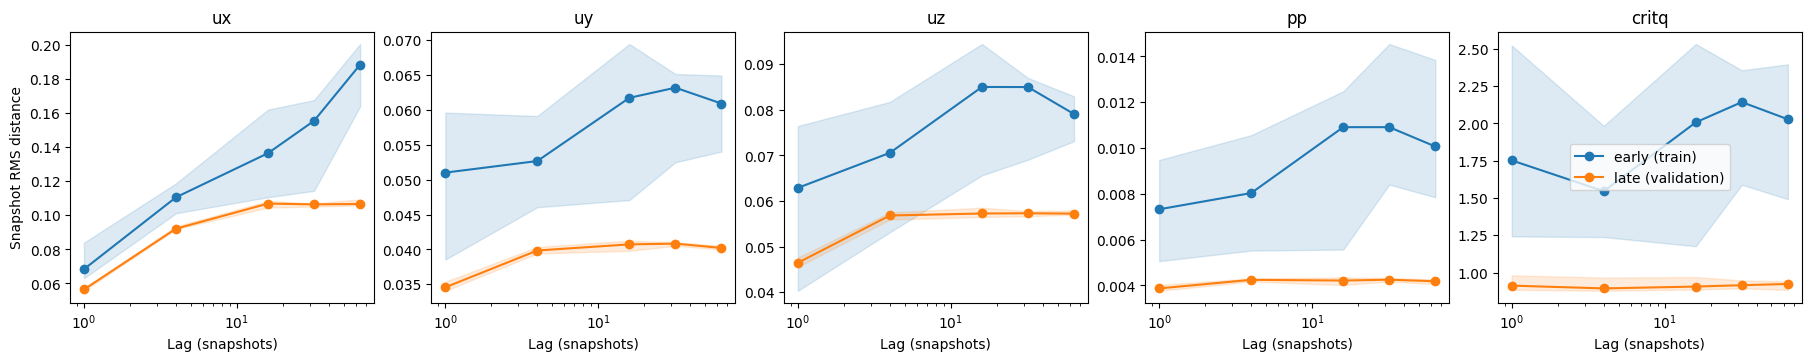

In [5]:
fig, axes = plt.subplots(1, len(COMPONENTS), figsize=(18, 3.5), layout='constrained')
for component, ax in zip(COMPONENTS, axes):
    for label, group in summary[summary['component'] == component].groupby('window'):
        lag = group['lag'].to_numpy()
        line, = ax.plot(lag, group['median'].to_numpy(), marker='o', label=label)
        ax.fill_between(lag, group['p10'].to_numpy(), group['p90'].to_numpy(),
                        color=line.get_color(), alpha=0.15)
    ax.set(xscale='log', xlabel='Lag (snapshots)', title=component)
axes[0].set_ylabel('Snapshot RMS distance')
axes[-1].legend()
plt.show()